# Actividad 1: Adquisición, EDA y Limpieza de Datos (AgroSmart Predict)

**Fuente:** `mohanty/PlantVillage` (Hugging Face)

**Objetivo:** Cargar el catálogo completo de registros de PlantVillage, realizar una inspección de calidad y análisis exploratorio (EDA), y generar la capa **silver** limpia y estructurada para su posterior carga en SQL.

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset

#Configuración de rutas relativas
RAW_DIR = os.path.join("..", "data", "raw")
SILVER_DIR = os.path.join("..", "data", "silver")
IMG_DIR = os.path.join("..", "docs", "img")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(SILVER_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

RAW_PATH = os.path.join(RAW_DIR, "plantvillage_raw.csv")
SILVER_PATH = os.path.join(SILVER_DIR, "plantvillage_silver.csv")

#Descarga desde Hugging Face (129.783 train + 33.133 test = 162.916 registros)
dataset = load_dataset("mohanty/PlantVillage", "default")
print(dataset)

#Unificar ambos splits conservando su origen
dfs = []
for split_name in dataset.keys():
    df_split = dataset[split_name].to_pandas()
    df_split["split"] = split_name
    dfs.append(df_split)

df_raw = pd.concat(dfs, ignore_index=True)

# Guardar copia original sin modificar en data/raw
df_raw.to_csv(RAW_PATH, index=False)
print(f"Muestra original guardada en {RAW_PATH} con dimensiones: {df_raw.shape}")
df_raw.head()

DatasetDict({
    train: Dataset({
        features: ['text'],
        num_rows: 129783
    })
    test: Dataset({
        features: ['text'],
        num_rows: 33133
    })
})
Muestra original guardada en ..\data\raw\plantvillage_raw.csv con dimensiones: (162916, 2)


,text,split
0,raw/color/Raspberry___healthy/a37f34f7-022d-46...,train
1,raw/color/Raspberry___healthy/368f3c83-5bd2-49...,train
2,raw/color/Raspberry___healthy/98226f66-15a1-40...,train
3,raw/color/Raspberry___healthy/e2bc5cd9-a590-4b...,train
4,raw/color/Raspberry___healthy/de3b86c7-8f0b-4c...,train


## 2. Inspección de calidad inicial (Capa Raw)

En esta fase evaluamos:

* Dimensiones totales, tipos de datos y valores nulos.

* Duplicados exactos en la columna `text`(ruta de la imagen.)

* Consistencia de la estructura de carpetas (`Raw/<Tipo_Imagen>/<Cultivo>__<Estado>/<Archivo>`).

In [9]:
print("--- DIAGNÓSTICO INICIAL (RAW) ---")
print(f"Filas totales: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
print("\nValores nulos por columna: \n", df_raw.isna().sum())

#Comprobar duplicados en la ruta completa y en el nombre de archivo
duplicados_ruta = df_raw.duplicated(subset=["text"]).sum()
print(f"\nRutas exactamente duplicadas: {duplicados_ruta}")

#Descomponer la ruta sin alterar mayúsculas del UUID original
df_eda = df_raw.copy()
df_eda["text_limpio"] = df_eda["text"].astype(str).str.strip()
partes = df_eda["text_limpio"].str.split("/")

#Verificar cuántas rutas cumplen el patrón esperado de 4 niveles: Raw / Tipo / Clase / Archivo
df_eda["num_niveles"] = partes.str.len()
print("\nDistribución de niveles en la ruta: \n", df_eda["num_niveles"].value_counts())

#Extraer campos cuando la estructura es válida (4 niveles y separador '___' en la clase)
df_eda["origen_carpeta"] = partes.str[0]
df_eda["tipo_imagen"] = partes.str[1]
df_eda["clase_completa"] = partes.str[2]
df_eda["nombre_archivo"] = partes.str[3]

#Verificar separador '___' entre cultivo y enfermedad
tiene_separador = df_eda["clase_completa"].str.contains("___", na=False)
print(f"Registros sin separador '___' en la clase: {(~tiene_separador).sum()}")

clase_split = df_eda["clase_completa"].str.split("___", n=1, expand=True)
df_eda["cultivo"] = clase_split[0]
df_eda["enfermedad"] = clase_split[1]

#Comprobar duplicados por nombre de archivo dentro del mismo tipo de imagen
duplicados_archivo = df_eda.duplicated(subset=["tipo_imagen", "clase_completa", "nombre_archivo"]).sum()
print(f"Duplicados por (tipo_imagen + clase + nombre_archivo): {duplicados_archivo}")

df_eda.head(10)

--- DIAGNÓSTICO INICIAL (RAW) ---
Filas totales: 162916 | Columnas: 2

Valores nulos por columna: 
 text     0
split    0
dtype: int64

Rutas exactamente duplicadas: 0

Distribución de niveles en la ruta: 
 num_niveles
4    162916
Name: count, dtype: int64
Registros sin separador '___' en la clase: 0
Duplicados por (tipo_imagen + clase + nombre_archivo): 0


,text,split,text_limpio,num_niveles,origen_carpeta,tipo_imagen,clase_completa,nombre_archivo,cultivo,enfermedad
0,raw/color/Raspberry___healthy/a37f34f7-022d-46...,train,raw/color/Raspberry___healthy/a37f34f7-022d-46...,4,raw,color,Raspberry___healthy,a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL...,Raspberry,healthy
1,raw/color/Raspberry___healthy/368f3c83-5bd2-49...,train,raw/color/Raspberry___healthy/368f3c83-5bd2-49...,4,raw,color,Raspberry___healthy,368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL...,Raspberry,healthy
2,raw/color/Raspberry___healthy/98226f66-15a1-40...,train,raw/color/Raspberry___healthy/98226f66-15a1-40...,4,raw,color,Raspberry___healthy,98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL...,Raspberry,healthy
3,raw/color/Raspberry___healthy/e2bc5cd9-a590-4b...,train,raw/color/Raspberry___healthy/e2bc5cd9-a590-4b...,4,raw,color,Raspberry___healthy,e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL...,Raspberry,healthy
4,raw/color/Raspberry___healthy/de3b86c7-8f0b-4c...,train,raw/color/Raspberry___healthy/de3b86c7-8f0b-4c...,4,raw,color,Raspberry___healthy,de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL...,Raspberry,healthy
5,raw/color/Raspberry___healthy/dbaa5f62-187f-42...,train,raw/color/Raspberry___healthy/dbaa5f62-187f-42...,4,raw,color,Raspberry___healthy,dbaa5f62-187f-422b-ac84-12c6e7b12025___Mary_HL...,Raspberry,healthy
6,raw/color/Raspberry___healthy/8e5806cd-b3f0-47...,train,raw/color/Raspberry___healthy/8e5806cd-b3f0-47...,4,raw,color,Raspberry___healthy,8e5806cd-b3f0-4737-8be0-9b7726d8b33c___Mary_HL...,Raspberry,healthy
7,raw/color/Raspberry___healthy/432379a4-dc5d-49...,train,raw/color/Raspberry___healthy/432379a4-dc5d-49...,4,raw,color,Raspberry___healthy,432379a4-dc5d-49fa-9d75-ebe05a1e01eb___Mary_HL...,Raspberry,healthy
8,raw/color/Raspberry___healthy/599c43e6-e742-4b...,train,raw/color/Raspberry___healthy/599c43e6-e742-4b...,4,raw,color,Raspberry___healthy,599c43e6-e742-4bc6-92a1-a1ebe4fa820a___Mary_HL...,Raspberry,healthy
9,raw/color/Raspberry___healthy/12a43ab6-1f18-4b...,train,raw/color/Raspberry___healthy/12a43ab6-1f18-4b...,4,raw,color,Raspberry___healthy,12a43ab6-1f18-4b10-9fb4-4865b216d28e___Mary_HL...,Raspberry,healthy


--- RESUMEN EXPLORATORIO (EDA) ---

1. Frecuencia por tipo de procesamiento de imagen:
tipo_imagen
segmented    54306
color        54305
grayscale    54305
Name: count, dtype: int64

2. Frecuencia por especie de cultivo (Top 15):
cultivo
Tomato                     54480
Orange                     16521
Soybean                    15270
Grape                      12187
Corn_(maize)               11556
Apple                       9513
Peach                       7971
Pepper,_bell                7425
Potato                      6456
Cherry_(including_sour)     5718
Squash                      5505
Strawberry                  4695
Blueberry                   4506
Raspberry                   1113
Name: count, dtype: int64

3. Proporción de hojas sanas vs con patología:
es_sana
False    72.22%
True     27.78%
Name: proportion, dtype: str


C:\Users\Usuario\AppData\Local\Temp\ipykernel_41500\2972127559.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=cultivos_counts.values, y=cultivos_counts.index, ax=axes[0], palette="viridis")


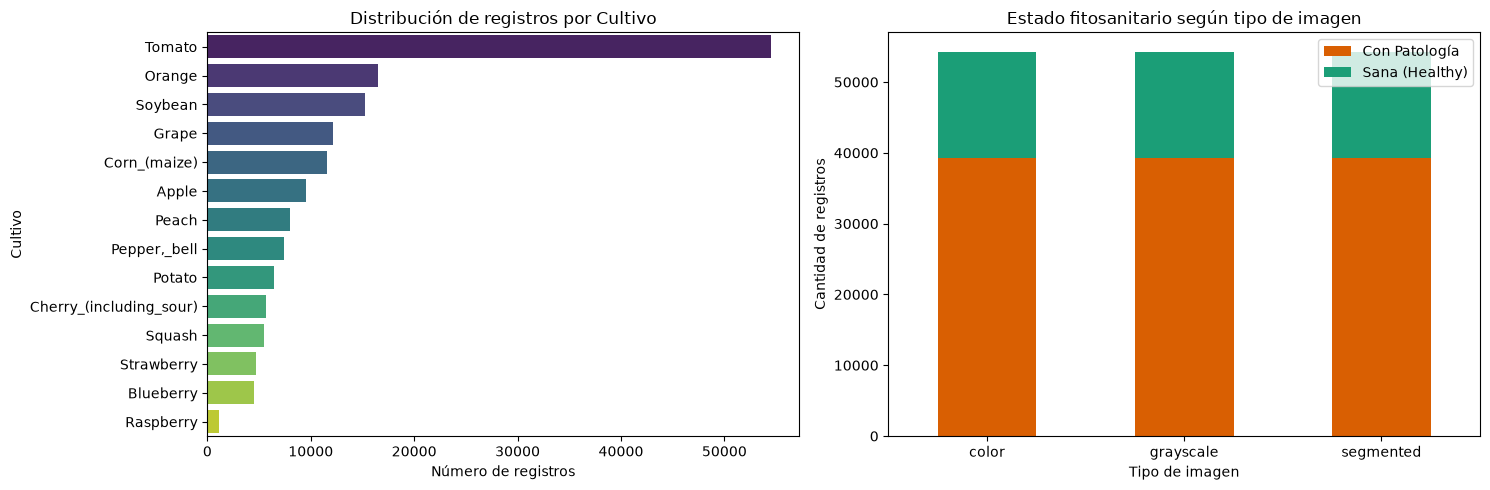

Gráfico guardado en: ..\docs\img\eda_plantvillage.png


In [10]:
print("--- RESUMEN EXPLORATORIO (EDA) ---")
print("\n1. Frecuencia por tipo de procesamiento de imagen:")
print(df_eda["tipo_imagen"].value_counts(dropna=False))

print("\n2. Frecuencia por especie de cultivo (Top 15):")
print(df_eda["cultivo"].value_counts(dropna=False))

#Crear indicador binario de planta sana vs enferma
df_eda["es_sana"] = df_eda["enfermedad"].str.lower().eq("healthy")
print("\n3. Proporción de hojas sanas vs con patología:")
print(df_eda["es_sana"].value_counts(normalize=True).mul(100).round(2).astype(str) + "%")

#Generación de gráficos para documentar en 01_phyton.md
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

#Gráfico 1: Distribución de registros por cultivo
cultivos_counts = df_eda["cultivo"].value_counts()
sns.barplot(x=cultivos_counts.values, y=cultivos_counts.index, ax=axes[0], palette="viridis")
axes[0].set_title("Distribución de registros por Cultivo")
axes[0].set_xlabel("Número de registros")
axes[0].set_ylabel("Cultivo")

#Gráfico 2: Proporcion Sano vs Enfermo por tipo de imagen
estado_tipo = pd.crosstab(df_eda["tipo_imagen"], df_eda["es_sana"])
estado_tipo.columns = ["Con Patología", "Sana (Healthy)"]
estado_tipo.plot(kind="bar", stacked=True, ax=axes[1], color=["#d95f02", "#1b9e77"])
axes[1].set_title("Estado fitosanitario según tipo de imagen")
axes[1].set_xlabel("Tipo de imagen")
axes[1].set_ylabel("Cantidad de registros")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
grafico_path = os.path.join(IMG_DIR, "eda_plantvillage.png")
plt.savefig(grafico_path, dpi=150)
plt.show()
print(f"Gráfico guardado en: {grafico_path}")


In [11]:
# --- PIPELINE DE LIMPIEZA A CAPA SILVER ---
df_silver = df_eda.copy()

#1. Filtar unicamente rutas válidas de 4 niveles y con separador '___'
condicion_valida = (df_silver["num_niveles"] == 4) & (df_silver["clase_completa"].str.contains("___", na=False))
registros_malformados = (~condicion_valida).sum()
df_silver = df_silver[condicion_valida].copy()

# 2. Normalizar texto de categorías (reemplazar guiones bajos por espacios, conservando UUID intacto)
df_silver["cultivo"] = df_silver["cultivo"].str.replace("_", " ", regex=False).str.strip().str.title()
df_silver["enfermedad"] = df_silver["enfermedad"].str.replace("_", " ", regex=False).str.strip().str.title()
df_silver["tipo_imagen"] = df_silver["tipo_imagen"].str.strip().str.title()

# 3. Eliminar duplicados exactos si existen (conservando primera aparicion)
antes_dedup =len(df_silver)
df_silver = df_silver.drop_duplicates(subset=["tipo_imagen", "cultivo", "enfermedad", "nombre_archivo"], keep="first")
duplicados_eliminados = antes_dedup - len(df_silver)

# 4. Seleccionar y ordenar columnas finales de la capa silver
columnas_silver = [
    "nombre_archivo",
    "split",
    "tipo_imagen",
    "cultivo",
    "enfermedad",
    "es_sana",
    "text_limpio"
]
df_silver = df_silver[columnas_silver].rename(columns={"text_limpio": "ruta_original"}).reset_index(drop=True)

# --- VALIDACIONES OBLIGATORIAS DE CALIDAD ---
assert df_silver.isna().sum().sum() == 0, "ERROR: Existen valores nulos en silver."
assert df_silver.duplicated(subset=["tipo_imagen", "cultivo", "enfermedad", "nombre_archivo"]).sum() == 0, "ERROR: Persisten duplicados."
assert set(df_silver["split"].unique()).issubset({"train", "test"}), "ERROR: Valores inesperados en split."
assert df_silver["es_sana"].dtype == bool, "ERROR: La columna es_sana debe ser booleana."

# Guardar capa silver
df_silver.to_csv(SILVER_PATH, index=False)

print("--- RESUMEN ANTES VS DESPUÉS ---")
print(f"Filas iniciales (Raw):                      {len(df_raw)}")
print(f"Registros mal formados:                     {registros_malformados}")
print(f"Duplicados eliminados:                      {duplicados_eliminados}")
print(f"Filas finales (Silver):                     {len(df_silver)}")
print(f"Columnas (Raw -> Silver):                   {df_raw.shape[1]} -> {df_silver.shape[1]}")
print(f"Nulos restantes en Silver:                  {df_silver.isna().sum().sum()}")
print(f"\nCapa SILVER generada correctamente en:    {SILVER_PATH}")
df_silver.head()

--- RESUMEN ANTES VS DESPUÉS ---
Filas iniciales (Raw):                      162916
Registros mal formados:                     0
Duplicados eliminados:                      0
Filas finales (Silver):                     162916
Columnas (Raw -> Silver):                   2 -> 7
Nulos restantes en Silver:                  0

Capa SILVER generada correctamente en:    ..\data\silver\plantvillage_silver.csv


,nombre_archivo,split,tipo_imagen,cultivo,enfermedad,es_sana,ruta_original
0,a37f34f7-022d-461a-8a3d-95f5cd774e35___Mary_HL...,train,Color,Raspberry,Healthy,True,raw/color/Raspberry___healthy/a37f34f7-022d-46...
1,368f3c83-5bd2-4906-b418-57b6ceff9bfe___Mary_HL...,train,Color,Raspberry,Healthy,True,raw/color/Raspberry___healthy/368f3c83-5bd2-49...
2,98226f66-15a1-40d5-9b62-04ae5b4fd8d5___Mary_HL...,train,Color,Raspberry,Healthy,True,raw/color/Raspberry___healthy/98226f66-15a1-40...
3,e2bc5cd9-a590-4b06-a610-dec52f74ae1e___Mary_HL...,train,Color,Raspberry,Healthy,True,raw/color/Raspberry___healthy/e2bc5cd9-a590-4b...
4,de3b86c7-8f0b-4cd8-ab11-2450fff0ec52___Mary_HL...,train,Color,Raspberry,Healthy,True,raw/color/Raspberry___healthy/de3b86c7-8f0b-4c...
